# Best and Worst TV shows
#### What Sperates the best 1000 TV shows and the worst 1000
#### Name: Tahoor Sheikh
#### ID: 100911158

# Introduction
IMDb also known as Internet Movie Database is one of the biggest sources for Movie and TV reviews. IMDb will display the top TV shows and its Average rating. Now a day there are Lots and Lots of differant TV shows all with differant genres and over a long period of time, with so many options it can be diffecult to choose what to watch and which genre to watch, from Drama to Action to Comedy. 

The Top 1000 list has TV shows that are Iconic like Breaking bad which is a Crime, Drama, Thriller all the way to TV shows like The Office which is one of the most popular Comedy shows ever made. While the Bottom 1000 list contains mainly forgetble TV shows with a rating lower than 5.0.

So then what separates good shows from bad, are certain generes more likely to get a higher rating? does the year the show released impact its rating in any signifficant way? These are the types of Questions that will be answered in this assignment. The database for the Top 1000 and worst 1000 TV shows was found on Kaggle.com which is a website that gives acccess to free databases.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/6/69/IMDB_Logo_2016.svg/1920px-IMDB_Logo_2016.svg.png" alt="IMDb" width="500" height="300">

# Methods

### Data Collection

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

top_1000 = pd.read_csv('data_top1000.csv')
bottom_1000 = pd.read_csv('data_bottom1000.csv')

In [4]:
display(top_1000.head())

,id,title,genres,averageRating,numVotes,releaseYear
0,tt0903747,Breaking Bad,"Crime, Drama, Thriller",9.5,2222284,2008
1,tt5491994,Planet Earth II,Documentary,9.5,161331,2016
2,tt0185906,Band of Brothers,"Drama, History, War",9.4,543090,2001
3,tt0795176,Planet Earth,"Documentary, Family",9.4,222856,2006
4,tt5152226,Tree of Life,Drama,9.4,11606,2014


In [5]:
display(bottom_1000.head())

,id,title,genres,averageRating,numVotes,releaseYear
0,tt5988370,Reis,"Biography, Drama",1.0,74161,2017
1,tt7221896,Cumali Ceber: Allah Seni Alsin,Comedy,1.0,39462,2017
2,tt13423846,321 Action,Drama,1.0,10212,2020
3,tt20255706,The Pogmentary,"Biography, Documentary, Sport",1.1,13807,2022
4,tt21403988,The Last Pharaoh,"Documentary, Drama, History",1.1,12020,2023


### Clean data
To clean up the data a little bit, I will remove the 'id' column and the 'numVotes' column, these columns will not be nessassary for the questions I will be answering.

In [6]:
top_1000 = top_1000.drop(['id','numVotes'],axis=1).dropna()
display(top_1000.head())

,title,genres,averageRating,releaseYear
0,Breaking Bad,"Crime, Drama, Thriller",9.5,2008
1,Planet Earth II,Documentary,9.5,2016
2,Band of Brothers,"Drama, History, War",9.4,2001
3,Planet Earth,"Documentary, Family",9.4,2006
4,Tree of Life,Drama,9.4,2014


In [7]:
bottom_1000 = bottom_1000.drop(['id','numVotes'],axis=1).dropna()
display(bottom_1000.head())

,title,genres,averageRating,releaseYear
0,Reis,"Biography, Drama",1.0,2017
1,Cumali Ceber: Allah Seni Alsin,Comedy,1.0,2017
2,321 Action,Drama,1.0,2020
3,The Pogmentary,"Biography, Documentary, Sport",1.1,2022
4,The Last Pharaoh,"Documentary, Drama, History",1.1,2023


# Analysis
I will be Answering the following questions
1. Which year after 2000 had the highest average rating for shows / which had the lowest?
2. What is the Highest rated genre on average / lowest?
3. What is more likely to be highly rated, live action, or animated shows?

### 1: Which year after 2000 had the highest average rating for shows / which had the lowest?

In [8]:
# First make a new dataframe filtering out the original to only inculde shows that were released in the year 2000 and after
# Do this for both top 1000 and bottom 2000
top_1000_2000s = top_1000[top_1000['releaseYear'] >= 2000]
bottom_1000_2000s = bottom_1000[bottom_1000['releaseYear'] >= 2000]

# Group the new dataframes with their average rating and find the mean
top_1000_2000s_group = top_1000_2000s.groupby("releaseYear")["averageRating"].mean()
bottom_1000_2000s_group = bottom_1000_2000s.groupby("releaseYear")["averageRating"].mean()

# Print the highest avaerge by finding the max in the top 1000
# Print the lowest average 
# ChatGPT was used to find the Index of the max i.e the .idxmax() funcntion 
# Prompt: how do I return the index of a max value in a grouped dataframe
# Output: To return the index (or indices) of the maximum value in a grouped DataFrame in Python (typically using pandas), 
# you can use the groupby method along with the idxmax function.
print(f"The year with the highest average rating for shows in the top 1000 (Best of the Best) was: {top_1000_2000s_group.idxmax()}")
print(f"Average rating: {round(top_1000_2000s_group.max(),2)}")

print(f"The year with the lowest average rating for shows in the top 1000 (Worst of the Best) was: {top_1000_2000s_group.idxmin()}")
print(f"Average rating: {round(top_1000_2000s_group.min(),2)}")

print(f"The year with the highest average rating for shows in the bottom 1000 (Best of the Worst) was: {bottom_1000_2000s_group.idxmax()}")
print(f"Average rating: {round(bottom_1000_2000s_group.max(),2)}")

print(f"The year with the lowest average rating for shows in the bottom 1000 (Worst of the Worst) was: {bottom_1000_2000s_group.idxmin()}")
print(f"Average rating: {round(bottom_1000_2000s_group.min(),2)}")

The year with the highest average rating for shows in the top 1000 (Best of the Best) was: 2001
Average rating: 8.63
The year with the lowest average rating for shows in the top 1000 (Worst of the Best) was: 2024
Average rating: 8.25
The year with the highest average rating for shows in the bottom 1000 (Best of the Worst) was: 2001
Average rating: 4.67
The year with the lowest average rating for shows in the bottom 1000 (Worst of the Worst) was: 2023
Average rating: 4.0


#### 1.1: Barplot of Top 1000 shows after the year 2000 and average rating

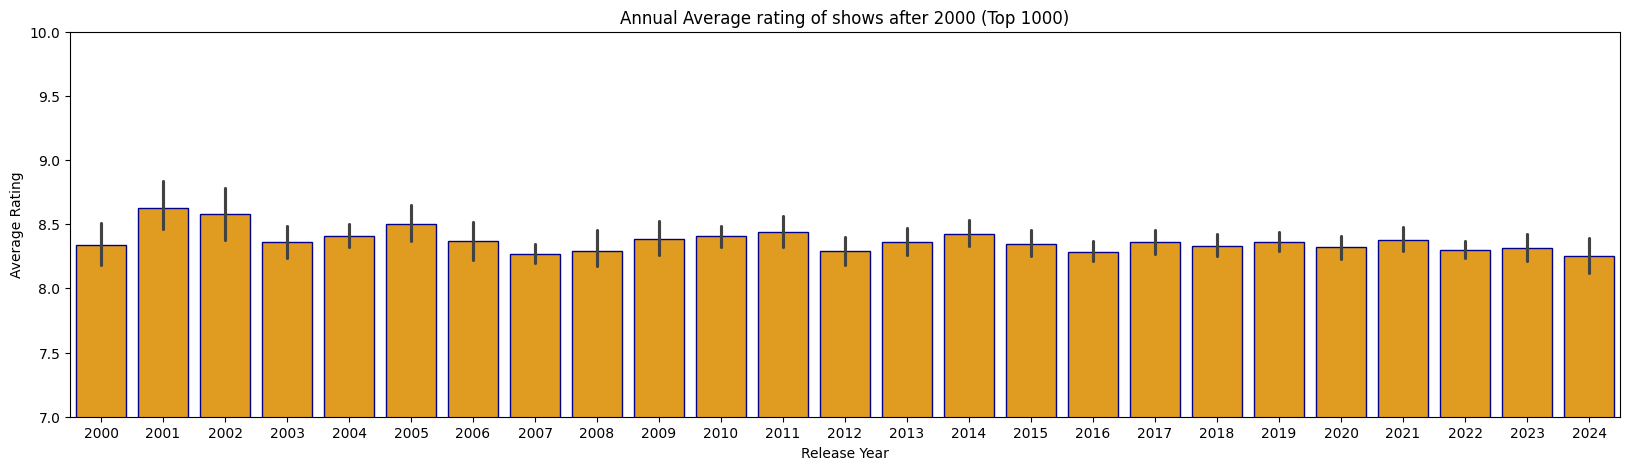

In [9]:
plt.figure(figsize=(20,5))
plt.ylim(7,10)
sns.set_theme(context="notebook")
p1 = sns.barplot(x = 'releaseYear',y = 'averageRating',data = top_1000_2000s,color="orange", edgecolor = "Darkblue")
p1 = p1.set(title="Annual Average rating of shows after 2000 (Top 1000)", xlabel="Release Year",ylabel="Average Rating")
plt.show()

#### 1.2: Barplot of bottom 1000 shows after the year 2000 and average rating

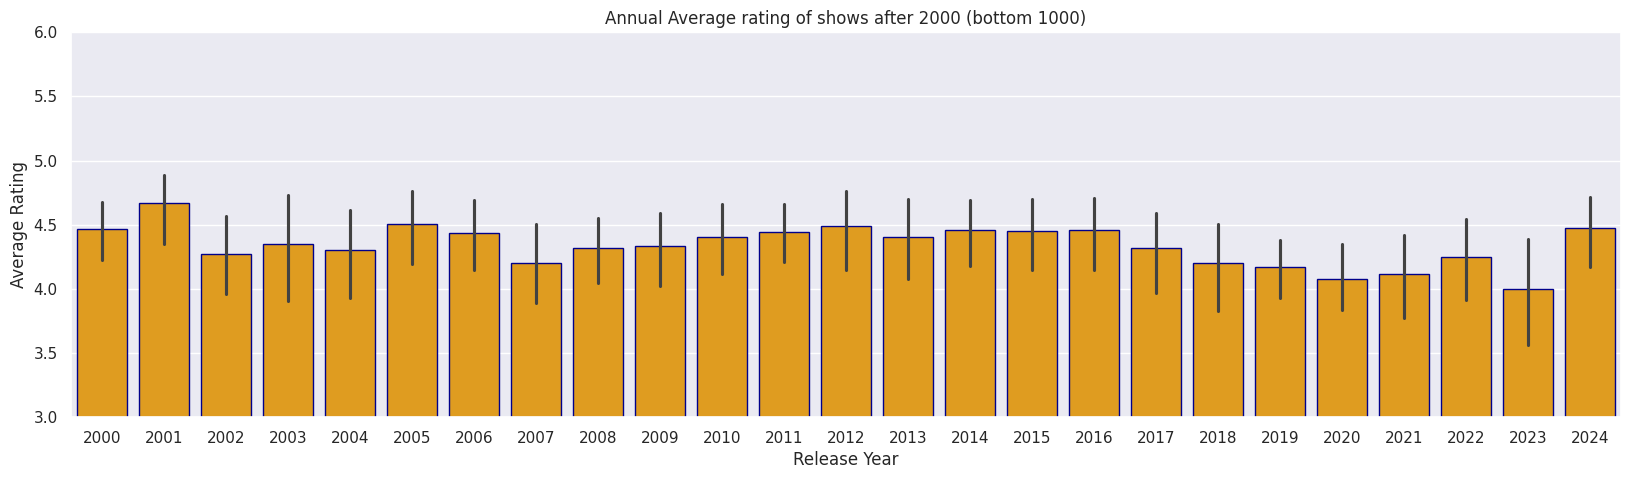

In [10]:
plt.figure(figsize=(20,5))
plt.ylim(3,6)
p2 = sns.barplot(x = 'releaseYear',y = 'averageRating',data = bottom_1000_2000s,color="orange", edgecolor = "Darkblue")
p2 = p2.set(title="Annual Average rating of shows after 2000 (bottom 1000)", xlabel="Release Year",ylabel="Average Rating")
plt.show()

#### 1.3: Lineplot of both data sets

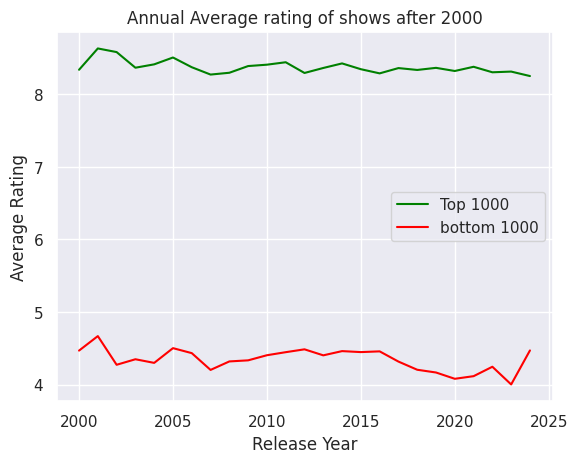

In [11]:
fig, ax = plt.subplots()
ax.plot(top_1000_2000s_group,color="Green",label="Top 1000")
ax.plot(bottom_1000_2000s_group,color="Red",label="bottom 1000")
ax.set_xlabel("Release Year")
ax.set_ylabel("Average Rating")
ax.set_title("Annual Average rating of shows after 2000")
ax.legend()

### 2: What is the Highest rated genre on average / lowest?

In [12]:
# Becasue the "genre" column can contain more than 1 genre, if we try to group the "genre" column with the "averageRating" column we will end up with too many diffrent combinations of genres, 
# so to simplify this we will only take the first genre that is listed aka if a Tv shows genre is "Crime, Drama, Thriller" 
# we will only take "Crime" as that will repersent the main genre of the Tv show
top_1000_genres_group = top_1000.groupby(top_1000["genres"].str.split(", ").str[0])[["averageRating"]].mean()
bottom_1000_genres_group = bottom_1000.groupby(bottom_1000["genres"].str.split(", ").str[0])[["averageRating"]].mean()

# print the highest and lowest average in the top 1000 and bottom 1000
print(f"The genre with the highest average rating for shows in the top 1000 (Best of the Best) was: {top_1000_genres_group.unstack().idxmax()[1]}")
print(f"Average rating: {round(top_1000_genres_group.unstack().max(),2)}")

print(f"The genre with the lowest average rating for shows in the top 1000 (Worst of the Best) was: {top_1000_genres_group.unstack().idxmin()[1]}")
print(f"Average rating: {round(top_1000_genres_group.unstack().min(),2)}")

print(f"The genre with the highest average rating for shows in the bottom 1000 (Best of the Worst) was: {bottom_1000_genres_group.unstack().idxmax()[1]}")
print(f"Average rating: {round(bottom_1000_genres_group.unstack().max(),2)}")

print(f"The genre with the lowest average rating for shows in the bottom 1000 (Worst of the Worst) was: {bottom_1000_genres_group.unstack().idxmin()[1]}")
print(f"Average rating: {round(bottom_1000_genres_group.unstack().min(),2)}")

The genre with the highest average rating for shows in the top 1000 (Best of the Best) was: Documentary
Average rating: 8.81
The genre with the lowest average rating for shows in the top 1000 (Worst of the Best) was: Fantasy
Average rating: 8.05
The genre with the highest average rating for shows in the bottom 1000 (Best of the Worst) was: Fantasy
Average rating: 4.74
The genre with the lowest average rating for shows in the bottom 1000 (Worst of the Worst) was: Talk-Show
Average rating: 2.5


#### 2.1: Barplot of Top 1000 and genres

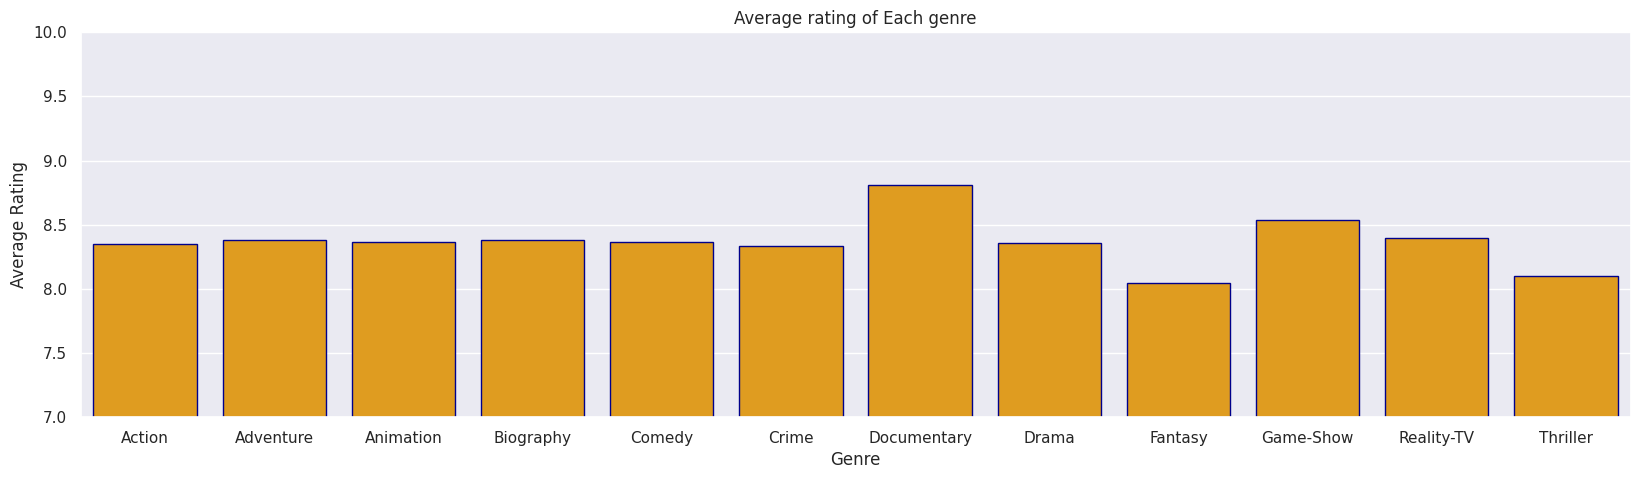

In [13]:
plt.figure(figsize=(20,5))
plt.ylim(7,10)
p3 = sns.barplot(x = 'genres',y = 'averageRating',data = top_1000_genres_group,color="orange", edgecolor = "Darkblue")
p3 = p3.set(title="Average rating of Each genre", xlabel="Genre",ylabel="Average Rating")
plt.show()

#### 2.2: Barplot of Bottom 1000 and genres

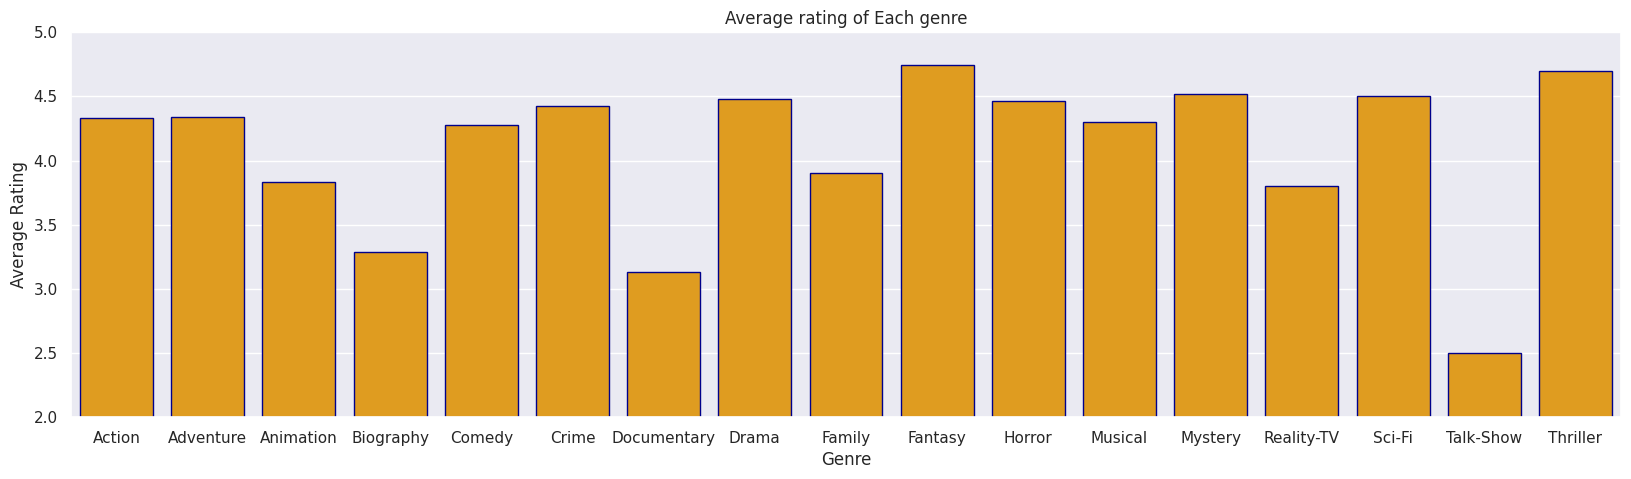

In [14]:
plt.figure(figsize=(20,5))
plt.ylim(2,5)
p4 = sns.barplot(x = 'genres',y = 'averageRating',data = bottom_1000_genres_group,color="orange", edgecolor = "Darkblue")
p4 = p4.set(title="Average rating of Each genre", xlabel="Genre",ylabel="Average Rating")
plt.show()

### 3: What is more likely to be highly rated, live action, or animated shows?

In [15]:
# Group the data frame by checking if the 'genre' column contains 'Animation' keyword and by average rating
top_1000_animated_group = top_1000.groupby(top_1000['genres'].str.contains("Animation"))["averageRating"].mean()

bottom_1000_animated_group = bottom_1000.groupby(bottom_1000['genres'].str.contains("Animation"))["averageRating"].mean()

# the index 'true' will return mean of shows that contain 'Animation' within their genre
# the index 'false' will return mean of shows that dont contain 'Animation' within their genre
print("The average rating of animated shows in the top 1000 is:",round(top_1000_animated_group[True],2))
print("The average rating of live action shows in the top 1000 is:",round(top_1000_animated_group[False],2))

print("The average rating of animated shows in the bottom 1000 is:",round(bottom_1000_animated_group[True],2))
print("The average rating of live action in the bottom 1000 is:",round(bottom_1000_animated_group[False],2))

The average rating of animated shows in the top 1000 is: 8.4
The average rating of live action shows in the top 1000 is: 8.36
The average rating of animated shows in the bottom 1000 is: 4.11
The average rating of live action in the bottom 1000 is: 4.34


#### 3.1: Barplot of data for animated and live action shows (top 1000)

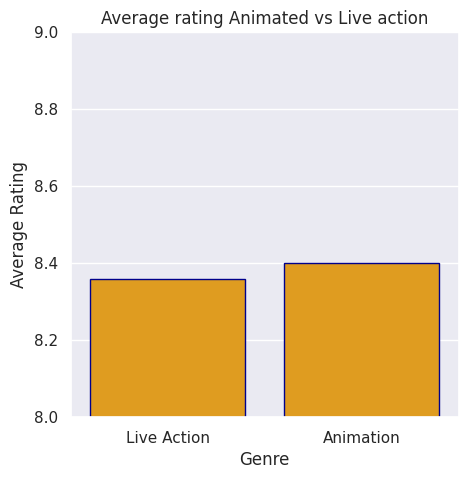

In [16]:
top_1000_animated_group = pd.DataFrame(top_1000_animated_group)
top_1000_animated_group['genres'] = ['Live Action','Animation']
plt.figure(figsize=(5,5))
plt.ylim(8,9)
p5 = sns.barplot(x = 'genres',y = 'averageRating',data = top_1000_animated_group,color="orange", edgecolor = "Darkblue")
p5 = p5.set(title="Average rating Animated vs Live action", xlabel="Genre",ylabel="Average Rating")
plt.show()

#### 3.2: Barplot of data for animated and live action shows (bottom 1000)

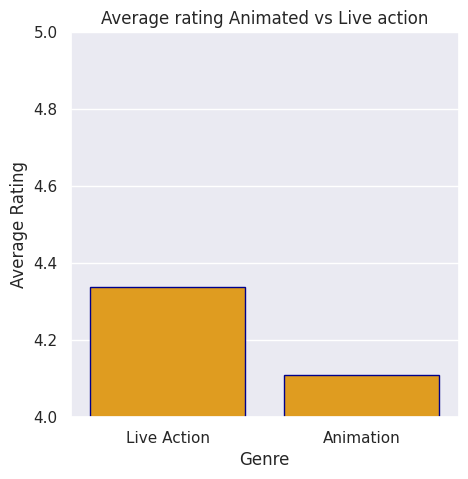

In [17]:
bottom_1000_animated_group = pd.DataFrame(bottom_1000_animated_group)
bottom_1000_animated_group['genres'] = ['Live Action','Animation']
plt.figure(figsize=(5,5))
plt.ylim(4,5)
p6 = sns.barplot(x = 'genres',y = 'averageRating',data = bottom_1000_animated_group,color="orange", edgecolor = "Darkblue")
p6 = p6.set(title="Average rating Animated vs Live action", xlabel="Genre",ylabel="Average Rating")
plt.show()

# Discussion
### 1: Summery of Question 1 (Which year after 2000 had the highest average rating for shows / which had the lowest?)
The findings from question 1 reveal that:\
The year with the highest average in the top 1000 was 2001 with an average rating of 8.63 (Best of the Best)\
The year with the lowest average in the top 1000 was 2024 with an average rating of 8.25 (Worst of the Best)\
The year with the highest average in the bottom 1000 was 2001 with an average rating of 4.67 (Best of the Worst)\
The year with the lowest average in the bottom 1000 was 2023 with an average rating of 4.0 (Worst of the Worst)

This Suggests that as the years go by the average rating of shows that reach the top 1000 / bottom 1000 is getting lower\
This can also mean that either, the quality of shows are decreasing or the expectaion of the audience is increasing over time\
This pattern can be seen in graphs 1.1, 1.2, and 1.3\
The line reperseting the top 1000 and bottom 1000 in graph 1.3 follow the same/similar pattern,\
Initially starting at a high point in 2001, then going down then back up but not higher than the previous peak which leads to the average decreasing over time

### 2: Summery of Question 2 (What is the Highest rated genre on average / lowest?)
The findings from question 2 reveal that:\
The genre with the highest average in the top 1000 was Documentary with an average rating of 8.81 (Best of the Best)\
The genre with the lowest average in the top 1000 was Fantasy with an average rating of 8.05 (Worst of the Best)\
The genre with the highest average in the bottom 1000 was Fantasy with an average rating of 4.74 (Best of the Worst)\
The genre with the lowest average in the bottom 1000 was Talk-Show with an average rating of 2.5 (Worst of the Worst)

This Suggests that Documentaries are the most likely to be high quality/highly rated on average,\
while Talk-shows are the most likely to be poor quality/low rated on average

When comparing the graphs of 2.1 and 2.2, graph 2.2 which repersents the bottom 1000 has more of a varaity of genres when compared to graph 2.1 which repersents the top 1000
This could suggest that some genres do not make it into the top 1000 as primary genres, for example, the 'horror' genre is seen in graph 2.2 but not 2.1 meaning in the top 1000 there is no show that has horror as its primary genre, however it is possible that it could be a secondary genre becasue when cleaning the data only the primary genre was taken into consideration

### 3: Summery of Question 3 (What is more likely to be highly rated, live action, or animated shows?)
The findings from question 3 reveal that:\
The average rating of Animated shows in the top 1000 is 8.4\
The average rating of Live action shows in the top 1000 is 8.36\
The average rating of Animated shows in the bottom 1000 is 4.11\
The average rating of Live action shows in the bottom 1000 is 4.34

This Suggests that within the top 1000 Animated shows are higher rated on average than live action shows\
While within the bottom 1000 Live action shows are higher rated on average than a Animated shows

This could mean than when an Animated show and a Live action show are done well, the Animated show will be higher quality / higher rated than the live action show\
while when an Animated show and a live action show are done poorly, the live action show will be higher quality / higher rated than the Animated show

One reason why Animated shows are higher rated could be that Animated shows allow for more creativity in artstyles and story telling that are harder to do or impossible in live action shows.
An example of this is a popular 3D Animated show 'Arcane' which is widely praised for its stunning Animation and artstyle, leading to a higher rating, According to IMDb User reviews, the show is often described as "Visually stunnung" and "Incredible animation".

# Conclusion
So in Conclusion\
The year with the highest rated shows on average was 2001, while the lowest was 2023\
Showing that the average rating of shows is decreasing over time, either due to higher expectaions or lower quality shows being produced

The genre with the highest rating on average was Documentaries, while the genre with the lowest were talk-shows
Showing that people might prefer shows that talk more in-depth about certain topics/issues

And finally That people will prefer an Animated show over a Live action show due to the more limitless creativity that can be expressed in Animation.

# References
https://www.kaggle.com/datasets/octopusteam/imdb-top-1000-tv-series\
https://www.kaggle.com/datasets/octopusteam/imdb-top-1000-worst-rated-titles\
https://www.geeksforgeeks.org/seaborn-barplot-method-in-python/\
https://stackoverflow.com/questions/42528921/how-to-prevent-overlapping-x-axis-labels-in-sns-countplot\
https://stackoverflow.com/questions/33227473/how-to-set-the-range-of-y-axis-for-a-seaborn-boxplot\
https://www.imdb.com/title/tt11126994/reviews/